<a id="chapter-20"></a>

# Chapter 20 · AlphaGo Zero and MuZero / AlphaGo Zero 与 MuZero

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 self-play + MCTS + policy/value network
- 掌握 PUCT 选择公式
- 区分已知规则模型与 MuZero 学习模型

**开始前最好已经会：**

- 理解 value/policy network
- 知道树搜索节点与边
- 熟悉 self-play 的概念


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Model-based vs model-free / board games | 概念对比 | 详细 |
| AlphaGo Zero: MCTS/self-play/training | PUCT 与闭环 | 详细 |
| Connect 4 AlphaZero implementation/results | 游戏、MCTS、模型、训练源码 | 完整 |
| MuZero high-level model/training | 三模型与 unroll loss | 详细 |
| Connect 4 MuZero | 节点、模型、搜索、数据 | 完整源码路线 |
| MuZero results / Atari | 结果与扩展 | 结构理解 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

网络擅长模式识别，搜索擅长向前推演。能否让二者互相改进，最后不依赖人类棋谱？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

搜索用网络先验引导，搜索访问次数形成更强策略目标；self-play 产生训练数据。MuZero 学习 representation、dynamics、prediction 三个函数，不直接重建原始观测。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $P(s,a)$ | 网络给出的动作先验 | 引导搜索初期 |
| $N(s,a)$ | 边访问次数 | 搜索积累的证据 |
| $Q(s,a)$ | 边的平均回传价值 | 利用项 |
| $\pi$ | MCTS visit-count 策略 | 训练 policy head 的目标 |
| $z$ | 最终比赛结果 | 训练 value head 的目标 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. PUCT 在利用与探索之间平衡

$$a=\arg\max_a[Q(s,a)+U(s,a)]$$

其中

$$U(s,a)=c_{puct}P(s,a)\frac{\sqrt{\sum_bN(s,b)}}{1+N(s,a)}$$

高 $Q$ 鼓励利用已知好动作；高 prior、低访问次数带来大 $U$，鼓励探索。随着某边被反复访问，分母增大，exploration bonus 下降。

### 2. 搜索怎样变成训练数据

根节点各动作访问次数产生更强策略目标

$$\pi(a|s)\propto N(s,a)^{1/\tau}$$

self-play 最终结果 $z$ 作为 value target。网络同时最小化

$$L=(z-v_\theta(s))^2-\pi^T\log p_\theta(s)+c\|\theta\|^2$$

新网络再为下一轮搜索提供更好先验与叶节点价值，形成 policy iteration 风格闭环。

### 3. MuZero 改变了什么

AlphaZero 搜索使用已知游戏规则。MuZero 学习三个函数：representation $h(o_{1:t})\to s_0$、dynamics $g(s_k,a_k)\to(s_{k+1},r_k)$、prediction $f(s_k)\to(p_k,v_k)$。隐藏状态只需保留对预测 reward/value/policy 有用的信息，不要求重建像素。

### 4. 回传时的玩家视角

零和轮流行动游戏中，子节点对下一玩家的正价值，对当前玩家通常是负价值。忘记在层级间翻转符号会让搜索偏好帮助对手。


## 4. 手算一个最小例子


三个动作的 $Q=[0.6,0.5,0.1]$，第三个动作虽然当前 Q 低，但 prior=0.5 且从未访问，其探索项最大，PUCT 可能优先尝试它。

访问后 $N$ 增加，若回传价值仍差，$U$ 下降，搜索会逐渐转向更可靠的动作。这就是“先验提出候选，搜索用证据修正”。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### PUCT 与训练目标

选择边：
$$a=\arg\max_a\left[Q(s,a)+c_{puct}P(s,a)\frac{\sqrt{\sum_bN(s,b)}}{1+N(s,a)}\right]$$

AlphaZero 风格损失：$L=(z-v)^2-\pi^T\log p+c\|\theta\|^2$。

MuZero 再学习隐藏状态转移 $s_{k+1}=g(s_k,a_k)$ 与预测 reward，并在 unroll 多步上累计 value/policy/reward loss。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $Q(s,a)$ | `q` | 当前边平均价值 |
| $P(s,a)$ | `prior` | policy head 先验概率 |
| $N(s,a)$ | `visits` | 每条边访问次数 |
| $U(s,a)$ | `c * prior * sqrt(parent_visits)/(1+visits)` | 探索项 |
| PUCT 选择 | `scores.argmax()` | 选择 Q+U 最大动作 |
| $\pi$ target | root visit counts 归一化 | 不是网络自身 argmax |

**从公式过渡到代码时：**下面实现单个节点的 PUCT 选择，直观看到高先验的未访问动作如何获得 exploration bonus。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

def puct_scores(q, prior, visits, c=1.5):
    parent_visits = max(1, visits.sum())
    exploration = c * prior * np.sqrt(parent_visits) / (1 + visits)
    return q + exploration

q = np.array([0.6, 0.5, 0.1])
prior = np.array([0.2, 0.3, 0.5])
visits = np.array([10, 4, 0])
scores = puct_scores(q, prior, visits)
print("PUCT scores:", np.round(scores, 3), "selected action:", scores.argmax())


PUCT scores: [0.702 0.837 2.906] selected action: 2


### 怎样读运行结果

示例应选择高 prior 且未访问的第三个动作。修改它的访问次数与 Q，观察选择如何转向。完整项目中重点追踪 selection、expansion、backup 和 root policy 四段。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
AlphaZero self-play：
对每个局面运行 MCTS：selection(PUCT) → expansion → network evaluation → backup
根访问次数形成 policy target π；按温度采样动作
终局结果 z 回填该局所有状态
训练网络最小化 value MSE + policy cross-entropy + regularization
用新网络继续 self-play，并通过评估决定是否替换

MuZero：representation 得初始 hidden；MCTS 中 dynamics 展开 action 得 reward/next hidden；
prediction 给 policy/value；训练时对 K 步 unroll 累计 reward/value/policy losses。
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

visits = np.array([30, 10, 0], dtype=float)
def visit_policy(visits, temperature):
    if temperature == 0:
        out = np.zeros_like(visits); out[visits.argmax()] = 1; return out
    weights = visits ** (1.0 / temperature)
    return weights / weights.sum()

for t in (1.0, 0.5, 0):
    print("temperature", t, "policy", visit_policy(visits, t))


temperature 1.0 policy [0.75 0.25 0.  ]
temperature 0.5 policy [0.9 0.1 0. ]
temperature 0 policy [1. 0. 0.]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`game.py`](../Chapter20/lib/game.py) | 状态编码、合法动作、胜负 | 先确保游戏规则 |
| [`test_game.py`](../Chapter20/tests/test_game.py) | 规则测试 | 可执行规范 |
| [`mcts.py`](../Chapter20/lib/mcts.py) | `find_leaf`, `search_batch`, `get_policy_value` | AlphaZero 搜索 |
| [`model.py`](../Chapter20/lib/model.py) | policy/value network | 训练输出 |
| [`train.py`](../Chapter20/train.py) | self-play + train | AlphaZero 闭环 |
| [`muzero.py`](../Chapter20/lib/muzero.py) | `ReprModel`, `DynamicsModel`, `PredModel`, `run_mcts`, `sample_batch` | MuZero 全流程 |
| [`train-mu.py`](../Chapter20/train-mu.py) | MuZero trainer | unroll targets 与同步 |

<details>
<summary>为什么按这个顺序读</summary>

先跑游戏测试再读搜索。AlphaZero `MCTS` 要检查同一状态在不同当前玩家视角下的 value 符号；batched search 还使用虚拟损失避免多个 leaf 请求重复路径。MuZero 中 `MCTSNode` 保存 prior、visit、value/reward；`expand_node` 调 dynamics/prediction，`backpropagate` 累积折扣 reward/value。训练 sample 必须将 episode 中的 action、reward、root policy 和最终 value 按 unroll 对齐。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**MCTS 根节点选择最佳动作的访问比例

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


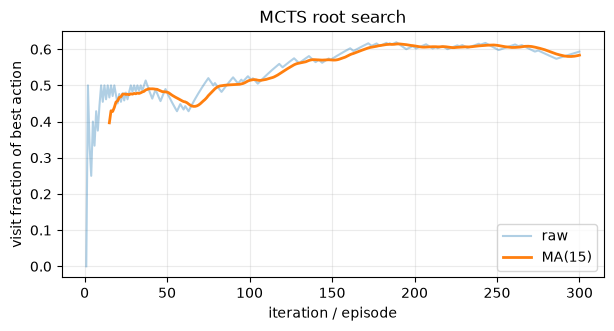

visits: [ 32 178  90] Q estimates: [0.344 0.702 0.578]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(20)
true_values = np.array([.35, .7, .5])
visits = np.zeros(3); value_sum = np.zeros(3); confidence = []
for simulation in range(1, 301):
    if (visits == 0).any():
        action = np.flatnonzero(visits == 0)[0]
    else:
        q = value_sum / visits
        action = np.argmax(q + 1.4 * np.sqrt(np.log(simulation) / visits))
    outcome = float(rng.random() < true_values[action])
    visits[action] += 1; value_sum[action] += outcome
    confidence.append(visits[true_values.argmax()] / simulation)

plot_curve(confidence, "MCTS root search", "visit fraction of best action", window=15)
print("visits:", visits.astype(int), "Q estimates:", np.round(value_sum / visits, 3))


### 曲线怎么读

搜索初期要探索所有动作，之后最佳动作访问比例总体上升。AlphaZero 训练还应同时看 policy loss、value loss、self-play 胜率和树搜索改进幅度。

### 调参过程：一次只改变一个因素

- 先用规则游戏测试合法动作、胜负和对称变换。
- 固定网络后调 simulations 与 exploration constant，记录搜索后策略相对先验的改进。
- 再调 replay window、temperature 和训练/自博弈比率。

### 失败案例复盘

- backup 时玩家视角符号没有交替，价值方向全错。
- 非法动作未 mask，policy 概率泄漏。
- 只和当前自己对弈，模型退化时没有历史 checkpoint 检测。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- MCTS value 回传时要按当前玩家视角正确翻转符号。
- 训练 target policy 来自 visit count，不是单次 argmax。
- 先对游戏规则和胜负判定写单元测试，再调网络。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把第三个动作 prior 降到 0.05 并重新归一化，观察选择；增加该动作访问次数后再比较。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

降低第三动作 prior 会减小其初始探索项；增加其 visit 又增大分母，使探索项继续下降。除非回传 Q 足够高，它会更不容易被选择。PUCT 中 prior 主要影响搜索早期，长期证据由 Q 与访问次数主导。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 网络提供先验和叶节点价值，MCTS 用模拟改进决策。
- visit counts 是 policy target，最终胜负是 value target。
- PUCT 的 Q 是利用项，U 是探索项。
- MuZero 学习用于规划的隐藏动态，而不是完整世界模拟。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么训练 policy head 使用访问次数而不是搜索选出的单个动作？MuZero dynamics 是否必须还原下一帧？

<details>
<summary>展开答案</summary>

访问分布包含搜索对多个动作的相对证据，信息比单个 argmax 更丰富。MuZero 隐藏动态只需支持 reward/value/policy 预测，不要求生成真实观测。
</details>


## 17. 与前后章节连接

第 21 章同样把网络价值与搜索组合，但目标从对抗棋局变成单智能体离散优化。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

根节点 Dirichlet noise 增加 self-play 多样性；temperature 控制 visit count 到动作概率的尖锐程度；MuZero 的 reanalyse 可用新网络重算旧数据目标。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-20) · [← 学习索引](README.md)
